# 06 · Visualization & Business Insights
**Part 4 of the assignment (20 %).** Eight static charts (PNG, 200 dpi) + an auto-generated findings file. Every chart reads the result tables written by notebooks 03–05 – nothing is typed in by hand, so **numbers in the report always match the data**.

| # | Figure | Question it answers |
|---|---|---|
| 1 | Daily revenue + 7-day average | How is revenue trending? |
| 2 | Revenue & profit by category | Which categories matter, and are they also the profitable ones? |
| 3 | Views vs sales (per product) | Is "most viewed" the same as "top selling"? |
| 4 | Conversion funnel | Where do shoppers drop out? |
| 5 | Purchase rate by device & referrer | Does the channel matter? |
| 6 | Customer segments & CLV concentration | Who are the valuable customers? |
| 7 | Cohort heat-map | Do older registration cohorts spend differently? |
| 8 | Traffic by weekday × hour | When do customers visit? |

In [11]:
import sys; sys.path.append("../src")
from config import *
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
PAL = sns.color_palette("deep")
rd = lambda n: pd.read_csv(TAB / f"{n}.csv")
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show(); print("saved", FIG / f"{name}.png")
FINDINGS = []      # (figure, sentence) - filled from the data below

## Figure 1 · Daily revenue with 7-day moving average

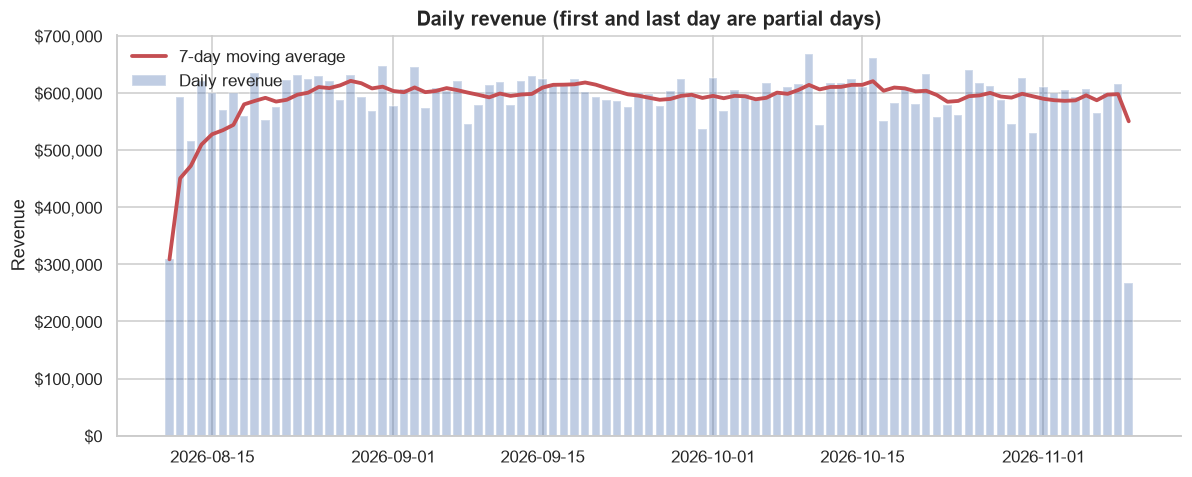

saved E:\bigdata\auca-ecommerce-analytics\outputs\figures\01_daily_revenue.png


In [12]:
d = rd("sql_daily_revenue_ma"); d["txn_date"] = pd.to_datetime(d.txn_date)
d_full = d.iloc[1:-1]                                   # first & last day are partial days
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(d.txn_date, d.revenue, color=PAL[0], alpha=.35, label="Daily revenue")
ax.plot(d.txn_date, d.revenue_ma7, color=PAL[3], lw=2.5, label="7-day moving average")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}")); ax.set_ylabel("Revenue"); ax.set_title("Daily revenue (first and last day are partial days)")
ax.legend(frameon=False); save(fig, "01_daily_revenue")
cv = d_full.revenue.std() / d_full.revenue.mean()
best = d_full.loc[d_full.revenue.idxmax()]
FINDINGS.append(("Revenue trend", f"Total revenue {d.revenue.sum():,.0f} over {len(d)} days ({d.orders.sum():,} orders). Daily revenue averages {d_full.revenue.mean():,.0f} with a coefficient of variation of {cv:.0%}; best day {best.txn_date:%Y-%m-%d} ({best.revenue:,.0f})."))

## Figure 2 · Revenue and estimated gross profit by category (top 10)

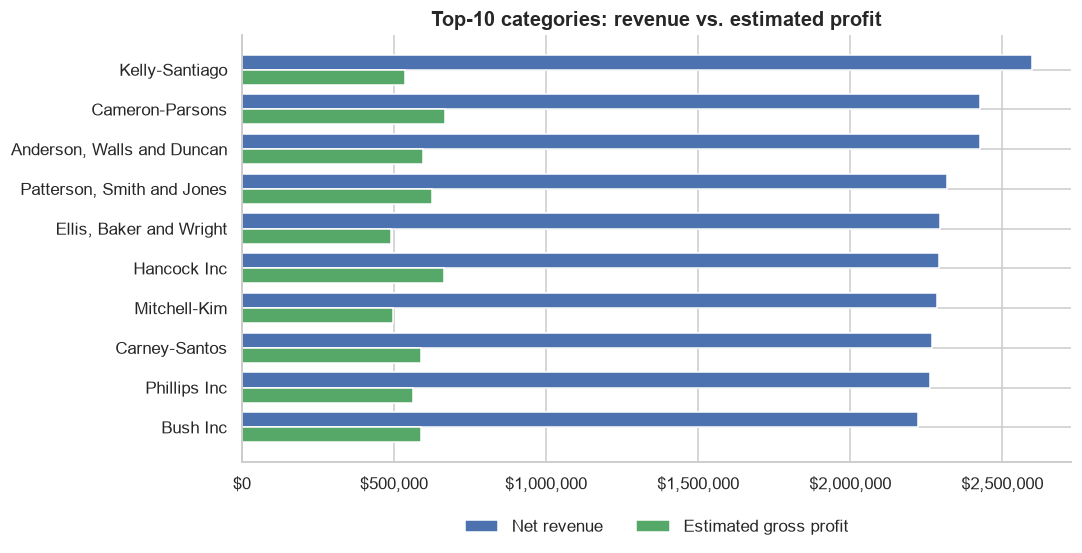

saved E:\bigdata\auca-ecommerce-analytics\outputs\figures\02_category_revenue_profit.png


In [13]:
c = rd("sql_category_conversion").sort_values("net_revenue", ascending=False).head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.2)); y = np.arange(len(c)); h = .38
ax.barh(y + h / 2, c.net_revenue, h, label="Net revenue", color=PAL[0]); ax.barh(y - h / 2, c.est_gross_profit, h, label="Estimated gross profit", color=PAL[2])
ax.set_yticks(y); ax.set_yticklabels(c.category_name); ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_title("Top-10 categories: revenue vs. estimated profit"); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2); save(fig, "02_category_revenue_profit")
all_c = rd("sql_category_conversion"); all_c["margin"] = all_c.est_gross_profit / all_c.net_revenue
top = all_c.sort_values("net_revenue", ascending=False).iloc[0]; best_m = all_c.sort_values("est_gross_profit", ascending=False).iloc[0]
FINDINGS.append(("Categories", f"Top category by revenue: {top.category_name} ({top.net_revenue:,.0f}); the most profitable is {best_m.category_name} ({best_m.est_gross_profit:,.0f} est. profit). Category margins range {all_c.margin.min():.0%}-{all_c.margin.max():.0%}, so revenue rank and profit rank differ."))

## Figure 3 · Top-selling vs. most-viewed products

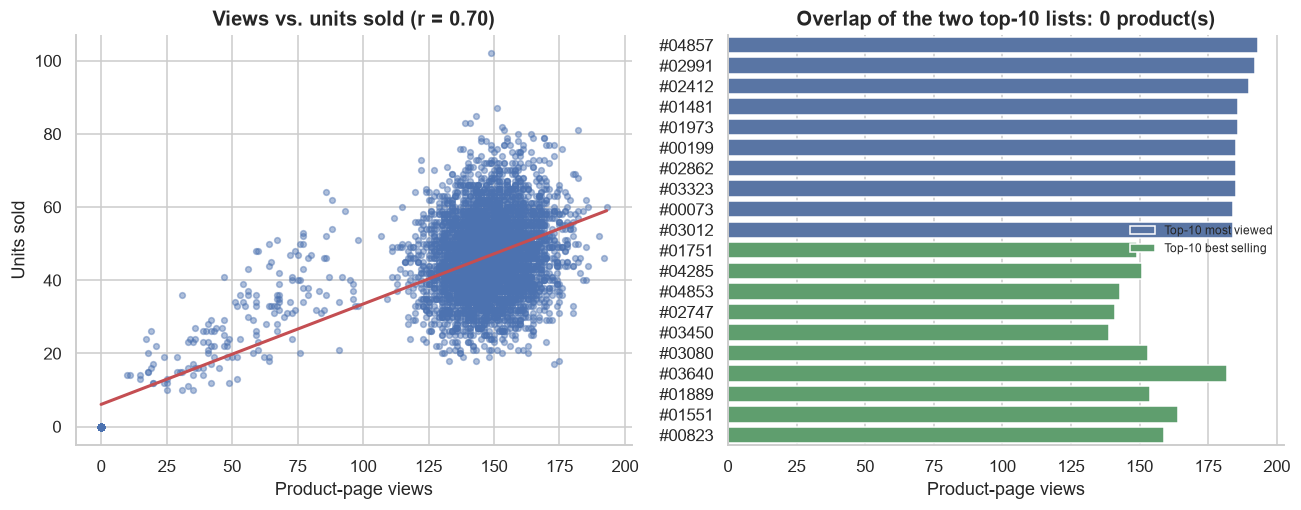

saved E:\bigdata\auca-ecommerce-analytics\outputs\figures\03_views_vs_sales.png


In [14]:
p = rd("sql_product_views_vs_sales")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]; ax.scatter(p.views, p.units_sold, s=14, alpha=.45, color=PAL[0])
m, b = np.polyfit(p.views, p.units_sold, 1); xs = np.linspace(p.views.min(), p.views.max(), 50); ax.plot(xs, m * xs + b, color=PAL[3], lw=2)
r = p[["views", "units_sold"]].corr().iloc[0, 1]; ax.set_xlabel("Product-page views"); ax.set_ylabel("Units sold"); ax.set_title(f"Views vs. units sold (r = {r:.2f})")
ax = axes[1]; both = pd.concat([p.nlargest(10, "views").assign(kind="Top-10 most viewed"), p.nlargest(10, "units_sold").assign(kind="Top-10 best selling")])
overlap = len(set(p.nlargest(10, "views").product_id) & set(p.nlargest(10, "units_sold").product_id))
sns.barplot(data=both.assign(pid=both.product_id.str.replace("prod_", "#")), y="pid", x="views", hue="kind", ax=ax, dodge=False, palette=[PAL[0], PAL[2]])
ax.set_title(f"Overlap of the two top-10 lists: {overlap} product(s)"); ax.set_ylabel(""); ax.set_xlabel("Product-page views"); ax.legend(frameon=False, fontsize=8)
save(fig, "03_views_vs_sales")
conv = p[p.views > 0].assign(rate=lambda x: x.units_sold / x.views)
FINDINGS.append(("Popularity", f"Views and units sold are correlated (r = {r:.2f}); only {overlap} of the 10 most-viewed products are also in the 10 best-selling list. Median units sold per view: {conv.rate.median():.2f}. Products with high views but low sales are candidates for price/page review."))

## Figure 4 · Conversion funnel (strict stages) and platform over-reporting

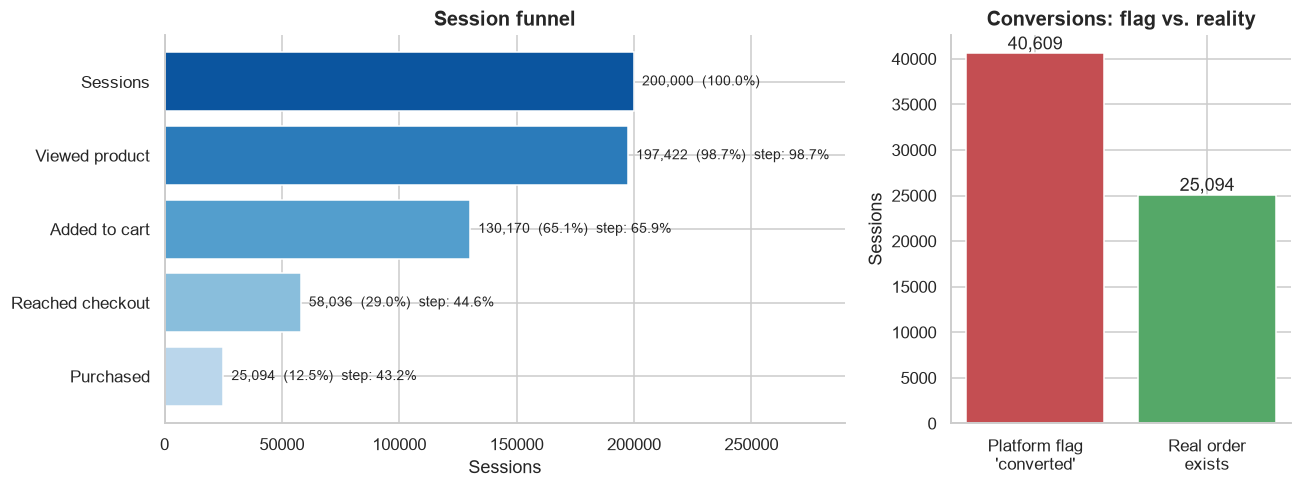

saved E:\bigdata\auca-ecommerce-analytics\outputs\figures\04_conversion_funnel.png


In [15]:
f = rd("int_funnel_overall"); v = rd("int_funnel_value").set_index("metric")["value"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]; yy = np.arange(len(f))[::-1]; ax.barh(yy, f.sessions, color=sns.color_palette("Blues_r", len(f) + 1)[:len(f)])
for yi, (s, pct, step) in zip(yy, zip(f.sessions, f.pct_of_all_sessions, f.step_conversion_pct)):
    ax.text(s, yi, f"  {s:,}  ({pct:.1f}%)" + ("" if np.isnan(step) else f"  step: {step:.1f}%"), va="center", fontsize=9)
ax.set_yticks(yy); ax.set_yticklabels(f.stage); ax.set_xlim(0, f.sessions.max() * 1.45); ax.set_title("Session funnel"); ax.set_xlabel("Sessions")
ax = axes[1]; raw, real = int(v["Sessions flagged 'converted' by the platform"]), int(v["Sessions with a real order"])
ax.bar(["Platform flag\n'converted'", "Real order\nexists"], [raw, real], color=[PAL[3], PAL[2]])
for i, x in enumerate([raw, real]): ax.text(i, x, f"{x:,}", ha="center", va="bottom")
ax.set_title("Conversions: flag vs. reality"); ax.set_ylabel("Sessions")
save(fig, "04_conversion_funnel")
drop = f.iloc[1:].sort_values("drop_off_sessions", ascending=False).iloc[0]
FINDINGS.append(("Funnel", f"{f.pct_of_all_sessions.iloc[-1]:.1f}% of sessions end in a purchase. Biggest step loss: before '{drop.stage}' ({int(drop.drop_off_sessions):,} sessions). The platform's 'converted' flag over-reports real conversions by {v['Platform over-reports conversions by']}."))
abandoned = int(v["Cart value abandoned (never 'converted')"])
failed = int(v["Cart value of failed checkouts (looked converted, no order)"])
bought = int(v["Cart value of purchased sessions"])
FINDINGS.append(("Revenue at stake", f"Abandoned carts hold {abandoned:,} in cart value; failed checkouts (flagged converted, no order - likely stock-outs) hold another {failed:,}, versus {bought:,} actually purchased."))

## Figure 5 · Purchase rate by device and by referrer

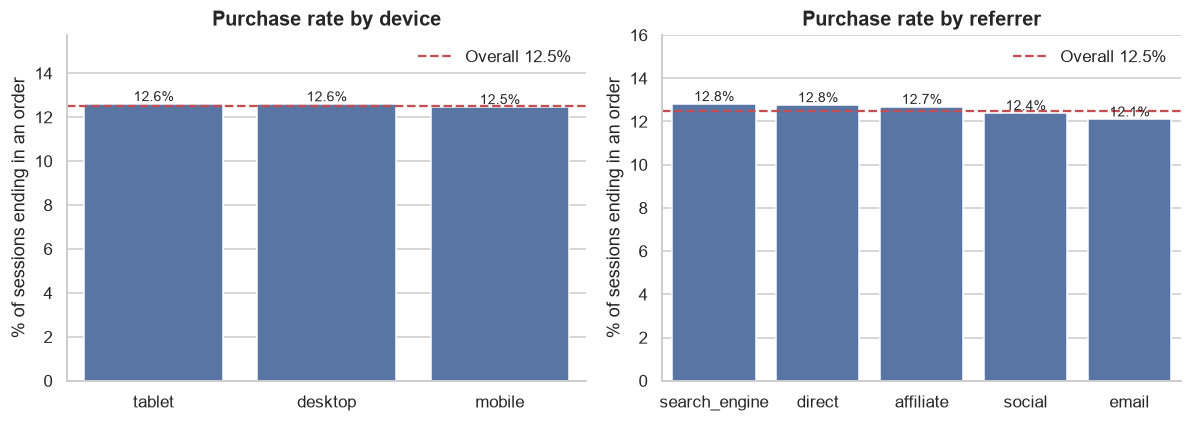

saved E:\bigdata\auca-ecommerce-analytics\outputs\figures\05_conversion_by_channel.png


In [16]:
dv, rf = rd("int_funnel_by_device"), rd("int_funnel_by_referrer")
fig, axes = plt.subplots(1, 2, figsize=(11, 4)); overall_rate = f.pct_of_all_sessions.iloc[-1]
for ax, df, col, title in [(axes[0], dv, "device_type", "By device"), (axes[1], rf, "referrer", "By referrer")]:
    df = df.sort_values("overall_purchase_pct", ascending=False)
    sns.barplot(data=df, x=col, y="overall_purchase_pct", ax=ax, color=PAL[0]); ax.axhline(overall_rate, color=PAL[3], ls="--", label=f"Overall {overall_rate:.1f}%")
    for i, val in enumerate(df.overall_purchase_pct): ax.text(i, val, f"{val:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Purchase rate {title.lower()}"); ax.set_ylabel("% of sessions ending in an order"); ax.set_xlabel(""); ax.set_ylim(0, df.overall_purchase_pct.max() * 1.25); ax.legend(frameon=False, loc="upper right")
save(fig, "05_conversion_by_channel")
FINDINGS.append(("Channels", f"Best referrer {rf.sort_values('overall_purchase_pct').iloc[-1].referrer} ({rf.overall_purchase_pct.max():.1f}%) vs worst {rf.sort_values('overall_purchase_pct').iloc[0].referrer} ({rf.overall_purchase_pct.min():.1f}%); device rates span only {dv.overall_purchase_pct.max() - dv.overall_purchase_pct.min():.2f} pp. Differences this small on random synthetic data should not drive channel decisions."))

## Figure 6 · Customer segments and CLV concentration

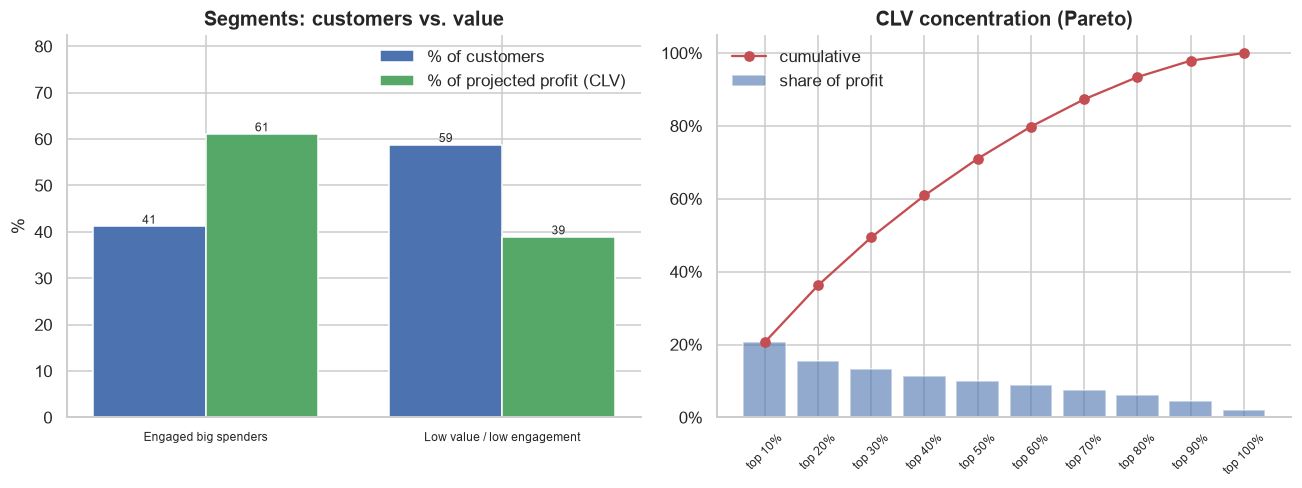

saved E:\bigdata\auca-ecommerce-analytics\outputs\figures\06_segments_clv.png


In [17]:
s, dec = rd("int_segment_profile").sort_values("avg_clv_12m", ascending=False), rd("int_clv_deciles").sort_values("decile")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]; x = np.arange(len(s)); w = .38
ax.bar(x - w / 2, s.share_of_users_pct, w, label="% of customers", color=PAL[0]); ax.bar(x + w / 2, s.share_of_clv_pct, w, label="% of projected profit (CLV)", color=PAL[2])
ax.set_xticks(x); ax.set_xticklabels([t.replace(", ", ",\n").replace(" (", "\n(") for t in s.segment], fontsize=8); ax.set_ylabel("%"); ax.set_title("Segments: customers vs. value"); ax.set_ylim(0, max(s.share_of_users_pct.max(), s.share_of_clv_pct.max()) * 1.35); ax.legend(frameon=False, loc="upper right", ncol=1)
for i, (a, b) in enumerate(zip(s.share_of_users_pct, s.share_of_clv_pct)): ax.text(i - w / 2, a, f"{a:.0f}", ha="center", va="bottom", fontsize=8); ax.text(i + w / 2, b, f"{b:.0f}", ha="center", va="bottom", fontsize=8)
ax = axes[1]; cum = dec.sort_values("decile", ascending=False).share_of_total_pct.cumsum().values
ax.bar(range(1, 11), dec.sort_values("decile", ascending=False).share_of_total_pct.values, color=PAL[0], alpha=.6, label="share of profit")
ax.plot(range(1, 11), cum, color=PAL[3], marker="o", label="cumulative"); ax.set_xticks(range(1, 11)); ax.set_xticklabels([f"top {i*10}%" for i in range(1, 11)], rotation=45, fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_title("CLV concentration (Pareto)"); ax.legend(frameon=False)
save(fig, "06_segments_clv")
top10 = dec.set_index("decile").loc[10, "share_of_total_pct"]; best_seg = s.iloc[0]
FINDINGS.append(("Customer value", f"The top 10% of customers generate {top10:.1f}% of projected 12-month profit. Best segment: '{best_seg.segment}' = {best_seg.share_of_users_pct:.0f}% of customers but {best_seg.share_of_clv_pct:.0f}% of projected profit (avg CLV {best_seg.avg_clv_12m:,.0f})."))
mm = rd("int_model_metrics"); bl, bst = mm.iloc[0], mm.iloc[1:].sort_values("rmse").iloc[0]
FINDINGS.append(("Predictive check", f"On held-out users, {bst.model} reaches RMSE {bst.rmse:,.0f} vs {bl.rmse:,.0f} for the run-rate baseline ({(1 - bst.rmse / bl.rmse):.0%} lower), but R² = {bst.r2:.2f}: engagement adds little beyond the average, as expected for synthetic data."))

## Figure 7 · Cohort heat-map (registration month × equal 30-day period)

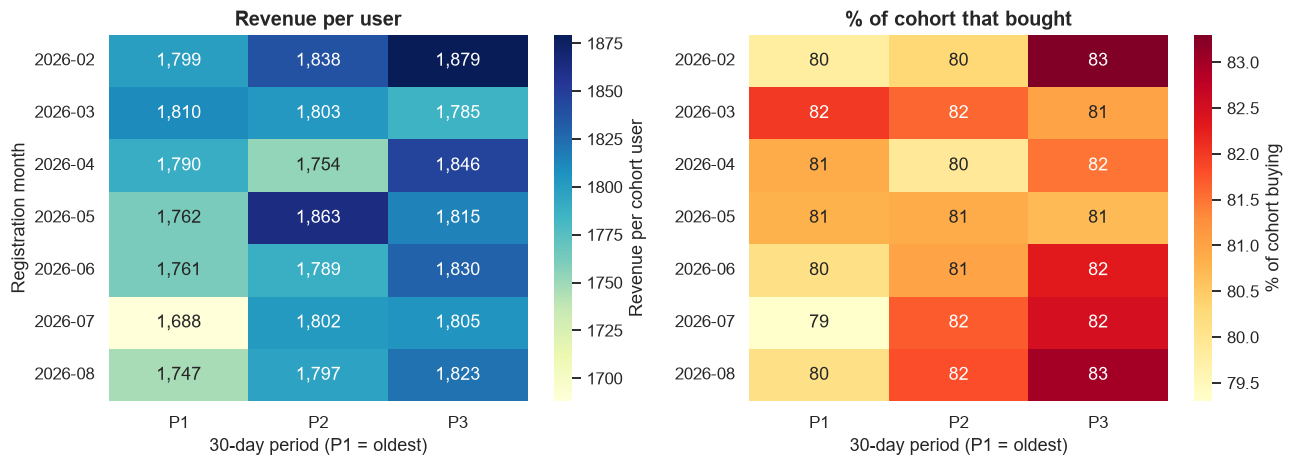

saved E:\bigdata\auca-ecommerce-analytics\outputs\figures\07_cohort_heatmap.png


In [18]:
co = rd("spark_cohort_periods"); piv = co.pivot(index="registration_month", columns="period", values="revenue_per_user"); piv.columns = [f"P{c}" for c in piv.columns]
rate = co.pivot(index="registration_month", columns="period", values="buyer_rate_pct"); rate.columns = piv.columns
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
sns.heatmap(piv, annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "Revenue per cohort user"}); axes[0].set_title("Revenue per user"); axes[0].set_ylabel("Registration month"); axes[0].set_xlabel("30-day period (P1 = oldest)")
sns.heatmap(rate, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "% of cohort buying"}); axes[1].set_title("% of cohort that bought"); axes[1].set_ylabel(""); axes[1].set_xlabel("30-day period (P1 = oldest)")
save(fig, "07_cohort_heatmap")
by_period = co.groupby("period").revenue_per_user.mean().round(0)
FINDINGS.append(("Cohorts", f"Revenue per cohort user ranges {piv.min().min():,.0f}-{piv.max().max():,.0f} across cohort/period cells; the average by 30-day period is " + ", ".join(f"P{p}: {x:,.0f}" for p, x in by_period.items()) + ". (Equal 30-day periods are used so every cell has the same exposure; compare the spread with the size of the cohorts before reading a trend into it.)"))

## Figure 8 · When do customers visit? (weekday × hour)

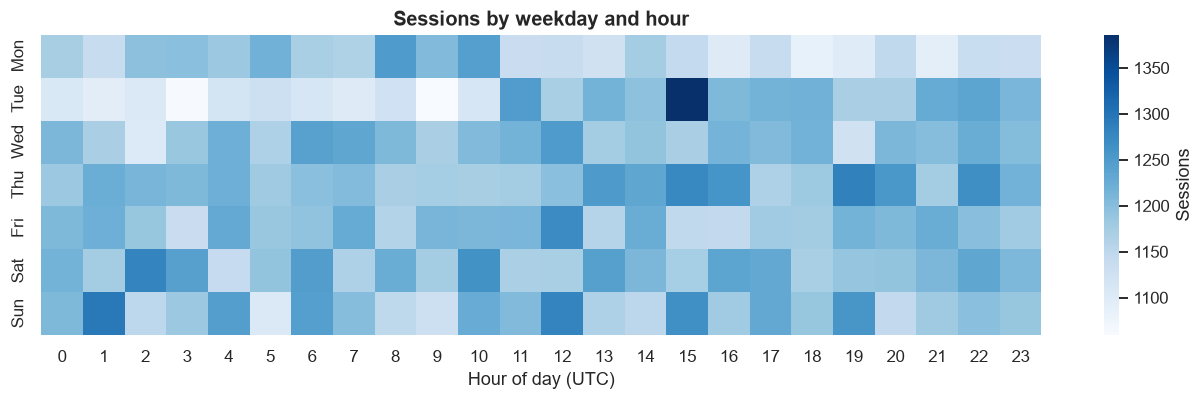

saved E:\bigdata\auca-ecommerce-analytics\outputs\figures\08_traffic_heatmap.png


In [19]:
h = rd("sql_hour_dow"); names = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
hp = h.pivot(index="dow_num", columns="hour", values="sessions").rename(index=names).reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
fig, ax = plt.subplots(figsize=(12, 3.8)); sns.heatmap(hp, cmap="Blues", ax=ax, cbar_kws={"label": "Sessions"}); ax.set_xlabel("Hour of day (UTC)"); ax.set_ylabel(""); ax.set_title("Sessions by weekday and hour")
save(fig, "08_traffic_heatmap")
peak = h.loc[h.sessions.idxmax()]
mean_s = h.sessions.mean(); cv_obs = h.sessions.std() / mean_s; cv_exp = 1 / np.sqrt(mean_s)       # Poisson noise: CV of a count ~ 1/sqrt(mean)
verdict = ("consistent with uniform random traffic - no staffing/campaign-timing conclusion is justified" if cv_obs < 1.3 * cv_exp
           else "more variable than chance alone would give - a real time-of-day pattern may exist")
FINDINGS.append(("Timing", f"Busiest slot: {names[int(peak.dow_num)]} {int(peak.hour):02d}:00 ({int(peak.sessions):,} sessions). Variation across the 168 weekday-hour slots is {cv_obs:.0%} of the mean, versus {cv_exp:.0%} expected from random counting noise alone: {verdict}."))

## Key findings (generated from the data)

In [20]:
out = ["# Key findings (auto-generated from outputs/tables)\n"]
for k, t in FINDINGS: out.append(f"- **{k}.** {t}")
dq = rd("data_quality_findings")
out.append("\n## Data-quality caveats that qualify every finding\n")
for _, r in dq.iterrows():
    if r.topic.startswith(("'converted'", "transactions WITHOUT", "products have", "users have")): out.append(f"- **{r.topic}**: {r.value} - {r.impact_on_design}")
(ROOT / "outputs" / "key_findings.md").write_text("\n".join(out), encoding="utf-8"); print("\n".join(out))

# Key findings (auto-generated from outputs/tables)

- **Revenue trend.** Total revenue 53,926,976 over 91 days (50,000 orders). Daily revenue averages 599,447 with a coefficient of variation of 5%; best day 2026-10-10 (668,503).
- **Categories.** Top category by revenue: Kelly-Santiago (2,597,128); the most profitable is Rodriguez-Graham (747,880 est. profit). Category margins range 18%-36%, so revenue rank and profit rank differ.
- **Popularity.** Views and units sold are correlated (r = 0.70); only 0 of the 10 most-viewed products are also in the 10 best-selling list. Median units sold per view: 0.32. Products with high views but low sales are candidates for price/page review.
- **Funnel.** 12.5% of sessions end in a purchase. Biggest step loss: before 'Reached checkout' (72,134 sessions). The platform's 'converted' flag over-reports real conversions by 62%.
- **Revenue at stake.** Abandoned carts hold 71,950,644 in cart value; failed checkouts (flagged converted, no order - likely 

### ✅ What you should have after this notebook
* `outputs/figures/01…08_*.png` – embed these in the report.
* `outputs/key_findings.md` – the insight sentences with numbers pulled from the data.

**Actionable recommendations to write up (each tied to a figure):**
1. **Fix checkout reliability / inventory sync** (Fig 4): sessions that look converted but have no order are lost revenue, not abandonment.
2. **Cart → checkout is the largest controllable drop** (Fig 4): test a cart reminder, shipping-cost transparency, guest checkout.
3. **Focus retention spend on the high-CLV segment** (Fig 6): a small share of customers carries most of the projected profit.
4. **Optimise for profit, not revenue** (Fig 2): promote high-margin categories.
5. **Be cautious about channel/timing conclusions** (Fig 5, 8): differences are within noise on this dataset – say so.